# Scam Drift: can yesterday's AI recognise tomorrow's scams?

**post-deadline v2 (Nov 18).** The judged hackathon entry is git `main` at commit `01abbc9`; it does not change. This notebook belongs to the post-deadline branch.

**User:** an English-reading grandparent and the family member who set up their phone. **Moment of use:** a text claims to come from a bank, a courier or a government office; before tapping the link, the grandparent pastes it into the checker. **Decision:** warn before they tap or reply. The tool currently fails non-English readers (section 13). The design is warn-only; it never blocks a message.

**What this notebook does.**
1. It downloads the public data if missing and imports the pipeline (`src/scam_drift.py`) and the prototype triage (`src/triage.py`).
2. It reads the results of the seeded run from `results/metrics.json` and `results/*.csv`. By default (`RUN_PIPELINE = False`) it does NOT retrain: it loads the saved seeded results. Set `RUN_PIPELINE = True` in section 1 to retrain every model and rewrite every result (about 2 minutes on CPU); the live check in section 12 then reproduces `metrics.json`.
3. It explains every v2 analysis (docs/V2_SPEC.md items 1-10) next to its numbers and figures.
4. It re-computes the prototype triage on the 2022-24 test live and checks it against `metrics.json`.

Labels: the benign twins are a **synthetic stress test, written with AI assistance**. Non-English results on English translations are an **oracle reference** (the translation came with the dataset). Years are **report-date cohorts** (the year shown in the reporter's screenshot), not send dates. Real modern legitimate SMS (India inbox, Mozambique) are shown only as aggregates: their raw texts contain first names.

This project is a prototype and is not financial advice.

## Colab only: get the code
This notebook needs the repository files (`src/`, `results/`, `models/`). In Colab, the next cell clones the repository and moves into it. It does nothing when the notebook already runs from the project root. The v2 notebook needs the `post-deadline` branch; the judged entry is `main` at `01abbc9`.

In [1]:
import sys, os
from pathlib import Path
REPO_URL, BRANCH = "https://github.com/KnigguKniggu-droid/scam-drift.git", "post-deadline"
if "google.colab" in sys.modules and not Path("src/triage.py").exists():
    !git clone --depth 1 --branch {BRANCH} {REPO_URL} scam-drift
    %cd scam-drift
print("working directory:", os.getcwd())

working directory: C:\Users\ganes\scam-drift


## 0. Setup
Install packages (Colab only), download the two public scam datasets if missing, write the synthetic benign-twins file if missing, and check the SHA-256 of the downloads. The real legitimate SMS sets (India inbox, MOZ) are downloaded by the pipeline from pinned Hugging Face revisions only when it runs; they are never published in this repository.

In [2]:
import os, sys, io, zipfile, urllib.request
from pathlib import Path
if "google.colab" in sys.modules:
    !pip -q install pandas==3.1.1 scikit-learn==1.9.1 matplotlib joblib  # the versions used for the published numbers
Path("data/raw").mkdir(parents=True, exist_ok=True)
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
IMC_URL = "https://raw.githubusercontent.com/reportsmishing/Smishing-Dataset-IMC25/main/dataset/final_dataset_output.csv"
if not Path("data/raw/SMSSpamCollection").exists():
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(UCI_URL).read())).extract("SMSSpamCollection", "data/raw")
if not Path("data/raw/imc25_smishing.csv").exists():
    urllib.request.urlretrieve(IMC_URL, "data/raw/imc25_smishing.csv")
TWINS_CSV = 'text,label,category,source\nYour First Harbor Bank verification code is 482913. It expires in 10 minutes. We will never call or text to ask for this code.,0,bank_otp,synthetic (written with AI assistance for this project)\n"482913 is your one-time passcode to sign in. Do not share it with anyone, including bank staff.",0,bank_otp,synthetic (written with AI assistance for this project)\n"Maple Credit Union: Use code 730245 to confirm your login. If you did not try to sign in, call the number on the back of your card.",0,bank_otp,synthetic (written with AI assistance for this project)\nYour security code is 118274. Never share this code. Our staff will never ask you for it.,0,bank_otp,synthetic (written with AI assistance for this project)\nG-552781 is your verification code.,0,bank_otp,synthetic (written with AI assistance for this project)\nYour code to approve the payment of $45.20 to City Water is 663019. Don\'t share it.,0,bank_otp,synthetic (written with AI assistance for this project)\nRiverside Bank: Your one-time code is 904416. Valid for 5 minutes. Reply HELP for help.,0,bank_otp,synthetic (written with AI assistance for this project)\n"Use 271839 to verify your new device. If this wasn\'t you, you can ignore this message.",0,bank_otp,synthetic (written with AI assistance for this project)\nYour login code is 3391. Enter it in the app to continue.,0,bank_otp,synthetic (written with AI assistance for this project)\nHealth portal: your sign-in code is 845120. It will expire in 15 minutes.,0,bank_otp,synthetic (written with AI assistance for this project)\nFirst Harbor Bank Fraud Alert: Did you use your card ending 4821 for $62.10 at Corner Grocery on Nov 3? Reply YES or NO. We will never ask for your PIN or code.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Maple Credit Union: We declined a card purchase of $899.00. If this was you, please try again. If not, call us at the number on the back of your card.",0,bank_alert,synthetic (written with AI assistance for this project)\nYour debit card ending 1190 was used for $20.00 at a gas station. No action needed if this was you.,0,bank_alert,synthetic (written with AI assistance for this project)\nLow balance alert: Your checking account ending 5532 is below $100.00.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Direct deposit of $1,245.67 received in your checking account ending 5532.",0,bank_alert,synthetic (written with AI assistance for this project)\nReminder: your credit card payment of $85.00 is due on Nov 25. Log in to your app to pay. Do not reply to this message.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Riverside Bank: A new payee was added to your account today. If you did not do this, call us using the number on your statement.",0,bank_alert,synthetic (written with AI assistance for this project)\nYour monthly statement is ready. Sign in to the mobile app to view it.,0,bank_alert,synthetic (written with AI assistance for this project)\nSecurity notice: we will never text you a link asking for your password or one-time code.,0,bank_alert,synthetic (written with AI assistance for this project)\n"Your pension payment of $1,512.00 was deposited today.",0,bank_alert,synthetic (written with AI assistance for this project)\nYour package from Oak Street Books was delivered to your front porch at 2:14 PM.,0,delivery,synthetic (written with AI assistance for this project)\nYour parcel will arrive tomorrow between 10am and 2pm. No action needed.,0,delivery,synthetic (written with AI assistance for this project)\nOut for delivery: your order #48211 will arrive today by 8pm.,0,delivery,synthetic (written with AI assistance for this project)\nWe left your package with your neighbour at number 12.,0,delivery,synthetic (written with AI assistance for this project)\nYour order has shipped. Track it at https://www.oakstreetbooks.com/orders,0,delivery,synthetic (written with AI assistance for this project)\nDelivery update: your parcel is delayed due to weather and will arrive Friday. We are sorry for the delay.,0,delivery,synthetic (written with AI assistance for this project)\nYour grocery order will arrive between 4pm and 5pm today. Your driver is Sam.,0,delivery,synthetic (written with AI assistance for this project)\nYour prescription delivery is on the way and will arrive this afternoon. Someone must sign for it.,0,delivery,synthetic (written with AI assistance for this project)\nPackage delivered to your mailbox. Thank you for shopping with us.,0,delivery,synthetic (written with AI assistance for this project)\nYour return has been received. Your refund of $24.99 will appear on your card in 3-5 days.,0,delivery,synthetic (written with AI assistance for this project)\nMaple Pharmacy: Your prescription is ready for pickup at our Main Street store. Reply STOP to opt out.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour refill for prescription #2231445 is ready. It will be held for 7 days.,0,pharmacy,synthetic (written with AI assistance for this project)\nReminder: it is time to refill your blood pressure medication. Call us or use the app to request a refill.,0,pharmacy,synthetic (written with AI assistance for this project)\nMaple Pharmacy: Your flu shot appointment is tomorrow at 10:30 AM. Please bring your insurance card.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour prescription could not be filled because it needs a new authorisation from your doctor. We have contacted your doctor\'s office.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour prescription order is being processed. We will text you when it is ready.,0,pharmacy,synthetic (written with AI assistance for this project)\nPharmacy reminder: your medication was not picked up and will be returned to stock in 2 days.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour copay for today\'s pickup is $10.00. Pay at the counter.,0,pharmacy,synthetic (written with AI assistance for this project)\nYour vaccine record is available. Ask the pharmacist if you need a printed copy.,0,pharmacy,synthetic (written with AI assistance for this project)\nMaple Pharmacy is closed on Thursday for the holiday. Our other store is open 9am to 5pm.,0,pharmacy,synthetic (written with AI assistance for this project)\n"Reminder: you have an appointment with Dr. Patel on Tuesday, Nov 12 at 9:00 AM. Reply C to confirm or R to reschedule.",0,medical,synthetic (written with AI assistance for this project)\nLakeside Clinic: Please arrive 15 minutes early for your appointment tomorrow and bring a list of your medicines.,0,medical,synthetic (written with AI assistance for this project)\nYour test results are available at https://portal.lakesideclinic.org or you can call the clinic.,0,medical,synthetic (written with AI assistance for this project)\nLakeside Clinic: Your eye exam is booked for Monday at 2:30 PM.,0,medical,synthetic (written with AI assistance for this project)\nDental reminder: your cleaning is on Friday at 11 AM. Call 555-0142 to change it.,0,medical,synthetic (written with AI assistance for this project)\nYour doctor has sent you a message. Please sign in to the patient portal to read it.,0,medical,synthetic (written with AI assistance for this project)\nHearing clinic: your new hearing aid batteries are ready to collect at the front desk.,0,medical,synthetic (written with AI assistance for this project)\nThis is a reminder to get your annual checkup. Call the office to book a time that suits you.,0,medical,synthetic (written with AI assistance for this project)\nLakeside Clinic: Your appointment has been cancelled because the doctor is unwell. We will call you to rebook.,0,medical,synthetic (written with AI assistance for this project)\nPhysical therapy reminder: your session is tomorrow at 1 PM. Wear comfortable clothes.,0,medical,synthetic (written with AI assistance for this project)\nCity Water: Your bill of $48.30 is due on Nov 28. You can pay by phone or at the office.,0,utility_other,synthetic (written with AI assistance for this project)\nYour electricity bill is ready. View it at https://www.brightpower.com/account,0,utility_other,synthetic (written with AI assistance for this project)\nYour phone bill of $35.00 was paid. Thank you.,0,utility_other,synthetic (written with AI assistance for this project)\nPower outage in your area. Crews are working and expect power back by 6 PM.,0,utility_other,synthetic (written with AI assistance for this project)\nLibrary: The book you reserved is ready for pickup. It will be held for 7 days.,0,utility_other,synthetic (written with AI assistance for this project)\nYour car is ready for pickup at Main Street Auto. Total: $212.40.,0,utility_other,synthetic (written with AI assistance for this project)\nSenior centre: Bingo is moved to Wednesday at 2 PM this week. See you there!,0,utility_other,synthetic (written with AI assistance for this project)\nYour new mobile plan starts on Dec 1. No action is needed.,0,utility_other,synthetic (written with AI assistance for this project)\nTown council: Trash pickup is delayed by one day this week because of the holiday.,0,utility_other,synthetic (written with AI assistance for this project)\nYour home insurance renewal documents have been mailed to you. Call your agent with any questions.,0,utility_other,synthetic (written with AI assistance for this project)\n"First Harbor Bank: Someone tried to sign in to your account. To cancel, reply with the code we just sent you.",1,bank_otp,synthetic (written with AI assistance for this project)\nThis is your bank\'s fraud team. We sent you a code to verify your identity. Please read it back to us to stop the transfer.,1,bank_otp,synthetic (written with AI assistance for this project)\nYour account will be locked. Share the 6-digit code you received with our agent to keep it open.,1,bank_otp,synthetic (written with AI assistance for this project)\n"Maple Credit Union: Your verification code is 730245. If you did not request this, call 1-800-555-0199 immediately to cancel.",1,bank_otp,synthetic (written with AI assistance for this project)\nVerify your account now: enter your one-time code at http://firstharbor-secure-login.com,1,bank_otp,synthetic (written with AI assistance for this project)\nWe noticed unusual activity. Reply with your code and PIN to confirm it is you.,1,bank_otp,synthetic (written with AI assistance for this project)\n"Your payment of $950.00 to John is pending. If this wasn\'t you, tell us the code we sent to cancel it.",1,bank_otp,synthetic (written with AI assistance for this project)\nFirst Harbor Bank Fraud Alert: Your card has been suspended due to suspicious activity. Verify now at http://fhb-verify-card.net,1,bank_alert,synthetic (written with AI assistance for this project)\n"Maple Credit Union: A charge of $899.00 was made at Electronics World. If not you, call 1-888-555-0123 now.",1,bank_alert,synthetic (written with AI assistance for this project)\nURGENT: Your bank account has been frozen. Click http://bit.ly/unlock-acct to restore access.,1,bank_alert,synthetic (written with AI assistance for this project)\nYour debit card ending 1190 has been blocked. Update your details within 24 hours: http://card-unlock-help.com,1,bank_alert,synthetic (written with AI assistance for this project)\nLow balance alert: we could not process your pension payment. Confirm your bank details at http://pension-update.info,1,bank_alert,synthetic (written with AI assistance for this project)\nSecurity notice: your online banking will be deactivated today unless you confirm your details at http://riverside-bank-secure.co,1,bank_alert,synthetic (written with AI assistance for this project)\nYour refund of $312.50 is waiting. Claim it now at http://refund-claim-center.com,1,bank_alert,synthetic (written with AI assistance for this project)\nYour package could not be delivered due to an incomplete address. Update it here: http://parcel-redelivery-help.com,1,delivery,synthetic (written with AI assistance for this project)\nDelivery failed. A $1.99 redelivery fee is required. Pay now at http://post-fee-pay.com or your parcel will be returned.,1,delivery,synthetic (written with AI assistance for this project)\nOut for delivery: your order #48211 is on hold. Confirm your details at http://track-order-status.net,1,delivery,synthetic (written with AI assistance for this project)\nWe tried to deliver your parcel today. Reschedule within 24 hours: http://bit.ly/resched-pkg,1,delivery,synthetic (written with AI assistance for this project)\nYour parcel is held at customs. Pay the $3.00 fee to release it: http://customs-release-fee.com,1,delivery,synthetic (written with AI assistance for this project)\nYour grocery order is delayed. Click here to get a $50 voucher for the trouble: http://freshvoucher.win,1,delivery,synthetic (written with AI assistance for this project)\nYour return could not be processed. Verify your card at http://returns-verify.com to receive your refund.,1,delivery,synthetic (written with AI assistance for this project)\nMaple Pharmacy: Your prescription is on hold. Confirm your insurance details at http://rx-hold-confirm.com,1,pharmacy,synthetic (written with AI assistance for this project)\nYour health insurance card has expired. Get a new card today by confirming your details at http://health-card-renew.com,1,pharmacy,synthetic (written with AI assistance for this project)\nCongratulations! You qualify for free diabetic supplies. Claim now: http://free-meds-claim.com,1,pharmacy,synthetic (written with AI assistance for this project)\nPharmacy reminder: your medication order failed. Update payment within 12 hours: http://rx-payment-update.net,1,pharmacy,synthetic (written with AI assistance for this project)\nGet your prescription drugs 80% off without a prescription. Order now: http://cheap-meds-online.biz,1,pharmacy,synthetic (written with AI assistance for this project)\nYour flu shot appointment requires a $25 deposit. Pay here to keep your slot: http://vaccine-slot-pay.com,1,pharmacy,synthetic (written with AI assistance for this project)\nLakeside Clinic: Your test results show a problem. Log in now to see them: http://lakeside-results-portal.co,1,medical,synthetic (written with AI assistance for this project)\n"Your appointment has been cancelled. To rebook, confirm your Social Security number at http://clinic-rebook.info",1,medical,synthetic (written with AI assistance for this project)\nYour health insurance will stop tomorrow. Call 1-877-555-0144 now to keep your coverage.,1,medical,synthetic (written with AI assistance for this project)\nYou are eligible for a free medical alert device. Reply YES to claim yours today!,1,medical,synthetic (written with AI assistance for this project)\nYour doctor has sent you a message. Sign in with your bank details to read it: http://patient-msg-login.com,1,medical,synthetic (written with AI assistance for this project)\nHearing aid recall: claim your free replacement now at http://hearing-recall-claim.com,1,medical,synthetic (written with AI assistance for this project)\nCity Water: Your water will be disconnected today due to an unpaid bill. Pay immediately at http://citywater-pay-now.com,1,utility_other,synthetic (written with AI assistance for this project)\nYour electricity will be shut off in 2 hours. Call 1-866-555-0177 to pay now.,1,utility_other,synthetic (written with AI assistance for this project)\nYour phone bill payment failed. Update your card at http://mobile-bill-update.com to avoid suspension.,1,utility_other,synthetic (written with AI assistance for this project)\n"Hi Grandma, it\'s me. I lost my phone and I\'m in trouble. Can you send $500 in gift cards? Don\'t tell Mum.",1,utility_other,synthetic (written with AI assistance for this project)\n"You have won $1,000,000 in the senior lottery! Claim your prize at http://senior-lotto-winner.com",1,utility_other,synthetic (written with AI assistance for this project)\nTown council: you have an unpaid parking fine. Pay within 24 hours to avoid court: http://council-fines-pay.com,1,utility_other,synthetic (written with AI assistance for this project)\nYour home insurance has lapsed. Renew now with 50% off: http://insure-renew-deal.com,1,utility_other,synthetic (written with AI assistance for this project)\n'
if not Path("data/benign_twins.csv").exists():
    Path("data/benign_twins.csv").write_text(TWINS_CSV, encoding="utf-8")
import hashlib
EXPECTED_SHA256 = {"data/raw/SMSSpamCollection": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
                   "data/raw/imc25_smishing.csv": "1bbd1e9e82c3ea023112207b80da268a5c4a07d2353c2b0898360ab037fa9a64"}
for f, h in EXPECTED_SHA256.items():
    ok = hashlib.sha256(Path(f).read_bytes()).hexdigest() == h
    print(f, "sha256 OK" if ok else "WARNING: file differs from the version used for the published numbers")
print(sorted(os.listdir("data/raw")))

data/raw/SMSSpamCollection sha256 OK
data/raw/imc25_smishing.csv sha256 OK
['SMSSpamCollection', 'extra', 'imc25_smishing.csv', 'readme', 'smsspam.zip']


In [3]:
import json, sys, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

if not Path("src/triage.py").exists():
    raise SystemExit("Run this notebook from the project root (the folder that holds src/, results/ and figures/). "
                     "In Colab, clone the repository first and cd into it.")
sys.path.insert(0, str(Path("src").resolve()))
import scam_drift as sd                      # pipeline; importing it does not run it
from triage import triage                    # shipped three-tier triage (src/triage.py)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

## 1. Run or load the pipeline
`RUN_PIPELINE = False` (default) reads the saved results of the seeded run, so this notebook does not overwrite them. Set it to `True` to re-run `src/scam_drift.py` end to end (seed 42). The run rewrites `results/`, `figures/` and `models/`; only `runtime_seconds` should change.

In [4]:
RUN_PIPELINE = False
if RUN_PIPELINE or not Path("results/metrics.json").exists():
    sd.main()
M = json.loads(Path("results/metrics.json").read_text(encoding="utf-8"))
V = M["v2"]
print("label:", V["label"], "| seed:", M["seed"], "| runtime_seconds:", M["runtime_seconds"])
print("metrics.json sha256:", hashlib.sha256(Path("results/metrics.json").read_bytes()).hexdigest()[:16])
R = lambda name: pd.read_csv(Path("results") / name)
fig = lambda name, w=820: display(Image(filename=str(Path("figures") / name), width=w))

label: post-deadline v2 (Nov 18) | seed: 42 | runtime_seconds: 125.4
metrics.json sha256: 6e9b2f220bdc30d8


## 2. Data and the shared normaliser
UCI 2012 SMS (deduplicated, stratified 80/20 split) and the IMC 2025 "Fishing for Smishing" reports. Only reports whose screenshot shows a year can be dated: scams dated up to 2021 may be used for training; scams dated 2022-24 are the untouched test; undated scams are never trained on.

The two datasets were anonymised differently (IMC25 writes `<URL>`, UCI keeps raw links). One normaliser maps links, phones, emails, money, dates and numbers in every source to shared tokens, then lowercases. Without it a model would learn "contains `<URL>` = modern dataset".

In [5]:
t0 = time.time()
d = sd.step_load_and_split()
print(f"loaded in {time.time() - t0:.1f} s")
display(pd.Series(d["info"]).to_frame("value"))
for t in ["WINNER!! Claim your prize: call 09061701461 or visit www.win-now.co.uk before 21st May",
          "Dear customer, your <NAMED_ENTITY> account is locked <URL> call <PHONE_NUMBER> on <DATE_TIME>"]:
    print(repr(t), "\n ->", sd.normalise(t))

loaded in 3.4 s


,value
imc_rows_total,33869
imc_rows_with_explicit_year,5295
imc_english_rows,22073
imc_english_unique_after_norm,15254
imc_english_dropped_overlap_with_uci,1
time_split_rule,train pool = English scams with explicit year <= 2021; test = explicit year >= 2022; undated rows never trained on
modern_early_train_n,1809
modern_late_test_n,1080
modern_undated_n,12364
modern_early_years,"[2015, 2016, 2017, 2018, 2019, 2020, 2021]"


'WINNER!! Claim your prize: call 09061701461 or visit www.win-now.co.uk before 21st May' 
 -> winner!! claim your prize: call tok_phone or visit tok_url before tok_date
'Dear customer, your <NAMED_ENTITY> account is locked <URL> call <PHONE_NUMBER> on <DATE_TIME>' 
 -> dear customer, your account is locked tok_url call tok_phone on tok_date


## 3. Every model on every test set (item 9a)
One row per model at its frozen threshold. Columns: UCI 2012 test precision and recall; recall on 2022-24 scams (n = 1,080) and on the cluster-safe version (n = 927, section 7); false-alarm rates on the held-out synthetic legit half (n = 30), on held-out real India legit SMS (n = 608, brand or template groups never seen in training) and on the Mozambique legit set (n = 1,608, Portuguese, never trained on).

Model names: `word_2012` / `char_2012` = UCI only. `word_fixed` / `char_fixed` = the **naive fix** (UCI + early modern scams; its only legitimate examples are 2012 texts). `fix_plus_benign` adds 30 synthetic legit texts. `fix_plus_real_ham` adds 598 real India legit SMS. `@fa_budget` = the strict threshold (at most 10% out-of-fold false alarms on the model's India training texts).

**Read this first:** the naive fix's high recall is not a win. It flags almost every legitimate modern text.

In [6]:
cmp = R("v2_model_comparison.csv")
display(cmp[["model", "threshold", "uci_precision", "uci_recall", "late_recall", "late_cluster_safe_recall",
             "synthetic_heldout_fa", "india_heldout_fa", "india_heldout_fa_ci95", "moz_fa"]])
s = V["real_ham_split"]
print("India split:", s["india_train_rows"], "train /", s["india_test_rows"], "test rows;",
      "brands on both sides:", s["brands_on_both_sides"], "; identical texts across:", s["identical_normalised_texts_across_split"])
print("Disclosure:", s["disclosure"])

,model,threshold,uci_precision,uci_recall,late_recall,late_cluster_safe_recall,synthetic_heldout_fa,india_heldout_fa,india_heldout_fa_ci95,moz_fa
0,rule_url_or_urgency,NaN,0.8364,0.3710,0.6185,0.5761,0.1000,0.4967,"[0.4571, 0.5363]",0.0199
1,rule_link_only,NaN,0.8636,0.1532,0.4065,0.3862,0.0667,0.4737,"[0.4343, 0.5134]",0.0199
2,rule_link_or_phone,NaN,0.9647,0.6613,0.5157,0.5102,0.1333,0.5362,"[0.4964, 0.5755]",0.3700
3,word_2012,0.32,0.9360,0.9435,0.7565,0.7314,0.3667,0.8224,"[0.79, 0.8507]",0.3937
4,char_2012,0.34,0.9512,0.9435,0.6944,0.7001,0.3667,0.8043,"[0.7709, 0.8339]",0.3719
5,word_fixed,0.24,0.7532,0.9597,0.9657,0.9601,1.0000,0.9951,"[0.9856, 0.9983]",0.6250
6,char_fixed,0.30,0.8676,0.9516,0.9602,0.9536,0.9667,0.9918,"[0.9809, 0.9965]",0.6667
7,fix_plus_benign,0.20,0.7018,0.9677,0.9741,0.9698,1.0000,0.9934,"[0.9832, 0.9974]",0.6443
8,char_fix_plus_benign,0.30,0.8731,0.9435,0.9574,0.9504,0.9000,0.9901,"[0.9786, 0.9955]",0.6847
9,fix_plus_real_ham,0.30,0.8603,0.9435,0.9481,0.9396,0.8667,0.6562,"[0.6176, 0.6929]",0.5305


India split: 598 train / 608 test rows; brands on both sides: 0 ; identical texts across: 0
Disclosure: Both sets were looked at during exploration (Nov 17) before these numbers were final.


The trade-off between catching new scams and false alarms on real legitimate texts, one point per model (left), and the operating curve: each line sweeps one model's threshold (descriptive only; thresholds were never chosen on test data).

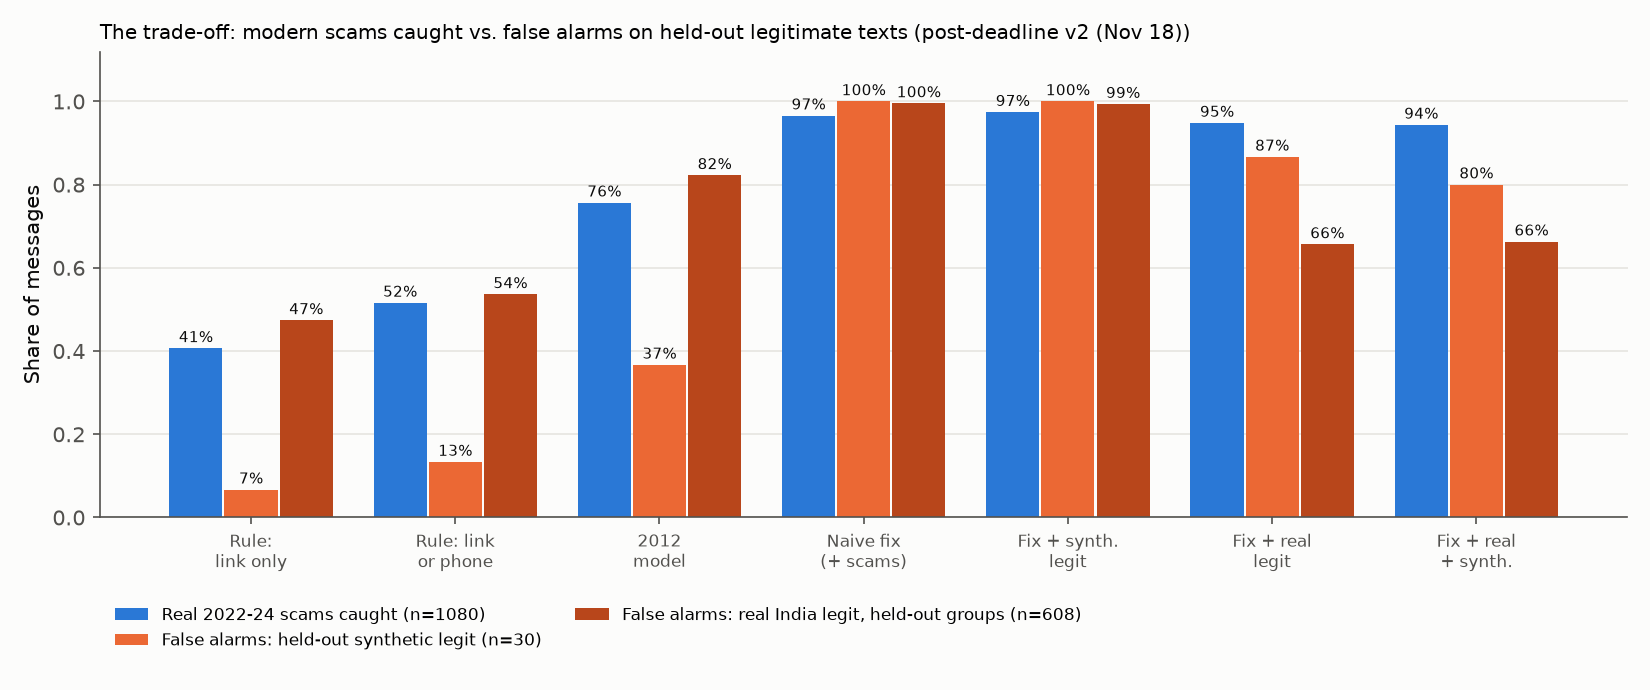

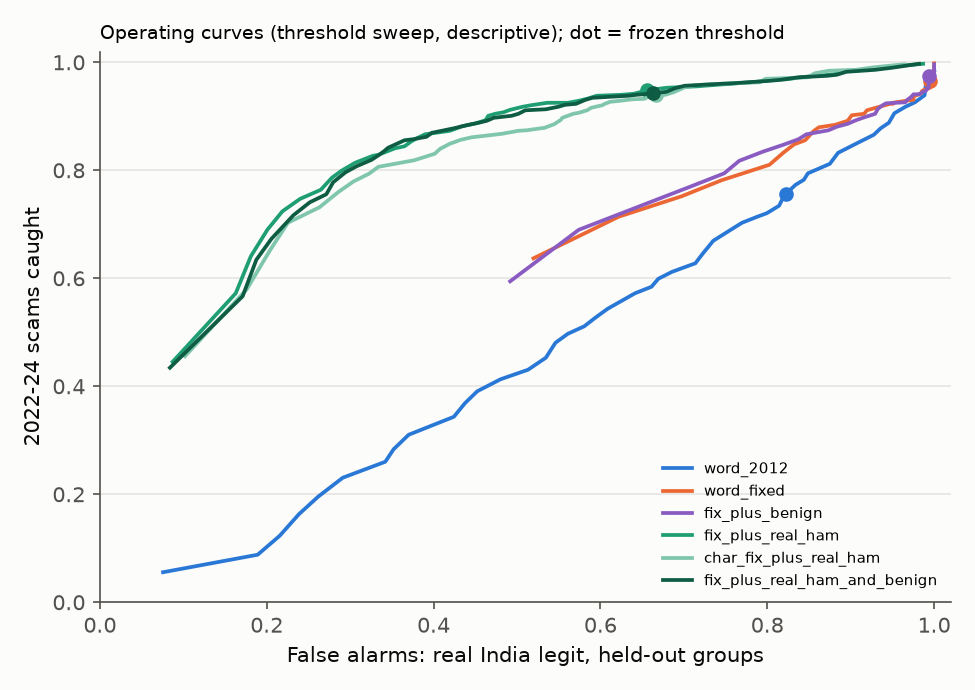

In [7]:
fig("tradeoff_catch_vs_false_alarm.png"); fig("operating_curve.png")

## 4. Source confound (item 1)
Can a simple classifier tell the sources apart? An AUC near 1.0 means yes: a model can learn the source (era, sender style) instead of "scam". UCI spam vs modern scams is the v1 shortcut check.

In [8]:
sc = V["source_confound"]
display(pd.DataFrame({"UCI spam vs modern scams": {"cv_roc_auc": M["shortcut_check"]["cv_roc_auc"]},
                      "UCI ham vs real India legit": {"cv_roc_auc": sc["uci_ham_vs_real_india_legit"]["cv_roc_auc"]},
                      "real India legit vs modern scams": {"cv_roc_auc": sc["real_india_legit_vs_modern_scam"]["cv_roc_auc"]}}).T)
print(sc["reading_rule"])

,cv_roc_auc
UCI spam vs modern scams,0.9893
UCI ham vs real India legit,0.9990
real India legit vs modern scams,0.9884


AUC near 0.5 = sources hard to tell apart; near 1.0 = easy (a shortcut a model can learn)


**Reading.** All three pairs are easy to tell apart. 2012 legitimate texts look nothing like 2020s legitimate texts, so a model trained with 2012 ham as its only legitimate examples learns "modern = scam". Adding 30 synthetic legit texts (`fix_plus_benign`) does not fix this on the 30 held-out synthetic texts from other categories (section 3).

## 5. URL shortcut (item 2)
Two rules: "flag if a link" and "flag if a link or a phone number". Then an ablation: remove every placeholder token (link, phone, email, money, date, number) from training and test texts, retrain, and re-choose the threshold by the same rule.

In [9]:
mc = V["model_comparison"]
rows = {k: {"2022-24 recall": mc[k]["late_recall"]["rate"], "synthetic legit FA": mc[k]["synthetic_legit_heldout_false_alarms"]["rate"],
            "India held-out FA": mc[k]["india_heldout_false_alarms"]["rate"], "MOZ FA": mc[k]["moz_false_alarms"]["rate"]}
        for k in ["rule_link_only", "rule_link_or_phone", "rule_url_or_urgency"]}
display(pd.DataFrame(rows).T)
pa = V["placeholder_ablation"]
print(pa["what"])
display(pd.DataFrame({k: v["change_vs_with_placeholders"] for k, v in pa.items() if isinstance(v, dict)}).T)

,2022-24 recall,synthetic legit FA,India held-out FA,MOZ FA
rule_link_only,0.4065,0.0667,0.4737,0.0199
rule_link_or_phone,0.5157,0.1333,0.5362,0.3700
rule_url_or_urgency,0.6185,0.1000,0.4967,0.0199


every tok_* placeholder (url, phone, email, money, date, num) removed from train and test texts; models retrained; thresholds re-chosen by the same out-of-fold cost rule


,late_recall,synthetic_legit_heldout_false_alarms,india_heldout_false_alarms,moz_false_alarms
word_fixed_no_placeholders,-0.0092,0.0000,-0.0181,-0.4366
fix_plus_real_ham_no_placeholders,0.0056,0.0666,0.0905,-0.1810


**Reading.** Removing all placeholders changes 2022-24 recall by less than one percentage point, so recall does not rest on the link token. It does lower MOZ false alarms a lot: on Portuguese texts the placeholders were doing much of the flagging.

## 6. Uncertainty and prevalence-adjusted precision (item 3)
Every rate on fewer than 1,000 messages carries a Wilson 95% interval. The modern test sets hold only scams or only legitimate texts, so precision is not defined on them directly. We show precision at an **ASSUMED** 5% scam rate (not measured): precision = 0.05 x recall / (0.05 x recall + 0.95 x false-alarm rate).

In [10]:
rows = {}
for k, v in mc.items():
    p = v["prevalence_adjusted_precision_assumed_5pct"]
    rows[k] = {"synthetic legit FA (n=30)": f'{v["synthetic_legit_heldout_false_alarms"]["rate"]} {v["synthetic_legit_heldout_false_alarms"]["ci95"]}',
               "precision@5% vs India": p["vs_india_heldout"], "precision@5% vs MOZ": p["vs_moz"],
               "precision@5% vs synthetic": p["vs_synthetic_heldout"]}
display(pd.DataFrame(rows).T)

,synthetic legit FA (n=30),precision@5% vs India,precision@5% vs MOZ,precision@5% vs synthetic
rule_url_or_urgency,"0.1 [0.0346, 0.2562]",0.0615,0.6206,0.2456
rule_link_only,"0.0667 [0.0185, 0.2132]",0.0432,0.5181,0.2429
rule_link_or_phone,"0.1333 [0.0531, 0.2968]",0.0482,0.0683,0.1692
word_2012,"0.3667 [0.2187, 0.5449]",0.0462,0.0918,0.0979
char_2012,"0.3667 [0.2187, 0.5449]",0.0435,0.0895,0.0906
word_fixed,"1.0 [0.8865, 1.0]",0.0486,0.0752,0.0484
char_fixed,"0.9667 [0.8333, 0.9941]",0.0485,0.0705,0.0497
fix_plus_benign,"1.0 [0.8865, 1.0]",0.0491,0.0737,0.0488
char_fix_plus_benign,"0.9 [0.7438, 0.9654]",0.0484,0.0685,0.053
fix_plus_real_ham,"0.8667 [0.7032, 0.9469]",0.0707,0.086,0.0544


## 7. Template leakage: cluster-safe split (item 4)
Scam campaigns reuse templates. If a template appears before and after the 2021/2022 cut, the "future" test is partly a copy of training data. We cluster all dated English scams (char_wb 3-5 TF-IDF, cosine > 0.8, connected components), date each cluster by its first report, and drop test rows whose cluster was already seen up to 2021.

In [11]:
cs = V["cluster_safe_split"]
display(pd.Series({k: v for k, v in cs.items() if k != "rule"}).to_frame("value"))
display(pd.DataFrame({k: {"2022-24 recall": mc[k]["late_recall"]["rate"], "cluster-safe recall": mc[k]["late_cluster_safe_recall"]["rate"]}
                      for k in ["word_2012", "word_fixed", "fix_plus_real_ham", "char_fix_plus_real_ham@fa_budget"]}).T)

,value
dated_rows,2889
clusters_total,2312
clusters_train_side,1497
clusters_test_side,815
clusters_spanning_the_cut,25
largest_cluster_rows,66
late_test_rows_before,1080
late_test_rows_removed,153
late_test_rows_cluster_safe,927
training_rows_unchanged,1809


,2022-24 recall,cluster-safe recall
word_2012,0.7565,0.7314
word_fixed,0.9657,0.9601
fix_plus_real_ham,0.9481,0.9396
char_fix_plus_real_ham@fa_budget,0.6519,0.6084


## 8. Filter half-life (item 5)
Time zero = the 2012 model's recall on held-out 2012 UCI spam. Then its recall on each report-date cohort. If recall fell steadily we could read off a half-life (the year recall halves). Second view: models retrained with a later cutoff year, tested 1-5 years after the cutoff.

time zero (UCI test spam): 0.9435 | without near-duplicates of training spam: 0.9205


,year,n,recall_word_2012,ci95,years_since_2012
0,2015,1,1.0000,"[0.2065, 1.0]",3
1,2016,3,0.6667,"[0.2077, 0.9385]",4
2,2017,126,0.8175,"[0.741, 0.8752]",5
3,2018,175,0.8000,"[0.7346, 0.8525]",6
4,2019,284,0.8345,"[0.7869, 0.8732]",7
5,2020,521,0.8042,"[0.768, 0.836]",8
6,2021,699,0.7454,"[0.7118, 0.7762]",9
7,2022,694,0.7450,"[0.7112, 0.776]",10
8,2023,378,0.7751,"[0.7304, 0.8143]",11
9,2024,8,0.8750,"[0.5291, 0.9776]",12


slope per year (cohorts n >= 100): -0.0117
half-life: not reached: no report-date cohort (n >= 30) falls to half of the time-zero recall


,cutoff_year,test_year,years_since_cutoff,n,train_modern_n,threshold,recall,ci95
0,2018,2019,1,284,305,0.49,0.9437,"[0.9105, 0.965]"
1,2018,2020,2,521,305,0.49,0.9482,"[0.9256, 0.9641]"
2,2018,2021,3,699,305,0.49,0.8727,"[0.8459, 0.8954]"
3,2018,2022,4,694,305,0.49,0.8847,"[0.8588, 0.9064]"
4,2018,2023,5,378,305,0.49,0.8915,"[0.8562, 0.919]"
5,2019,2020,1,521,589,0.34,0.9712,"[0.953, 0.9825]"
6,2019,2021,2,699,589,0.34,0.9056,"[0.8816, 0.9251]"
7,2019,2022,3,694,589,0.34,0.9308,"[0.9095, 0.9474]"
8,2019,2023,4,378,589,0.34,0.9259,"[0.895, 0.9483]"
9,2020,2021,1,699,1110,0.25,0.9328,"[0.9117, 0.9491]"


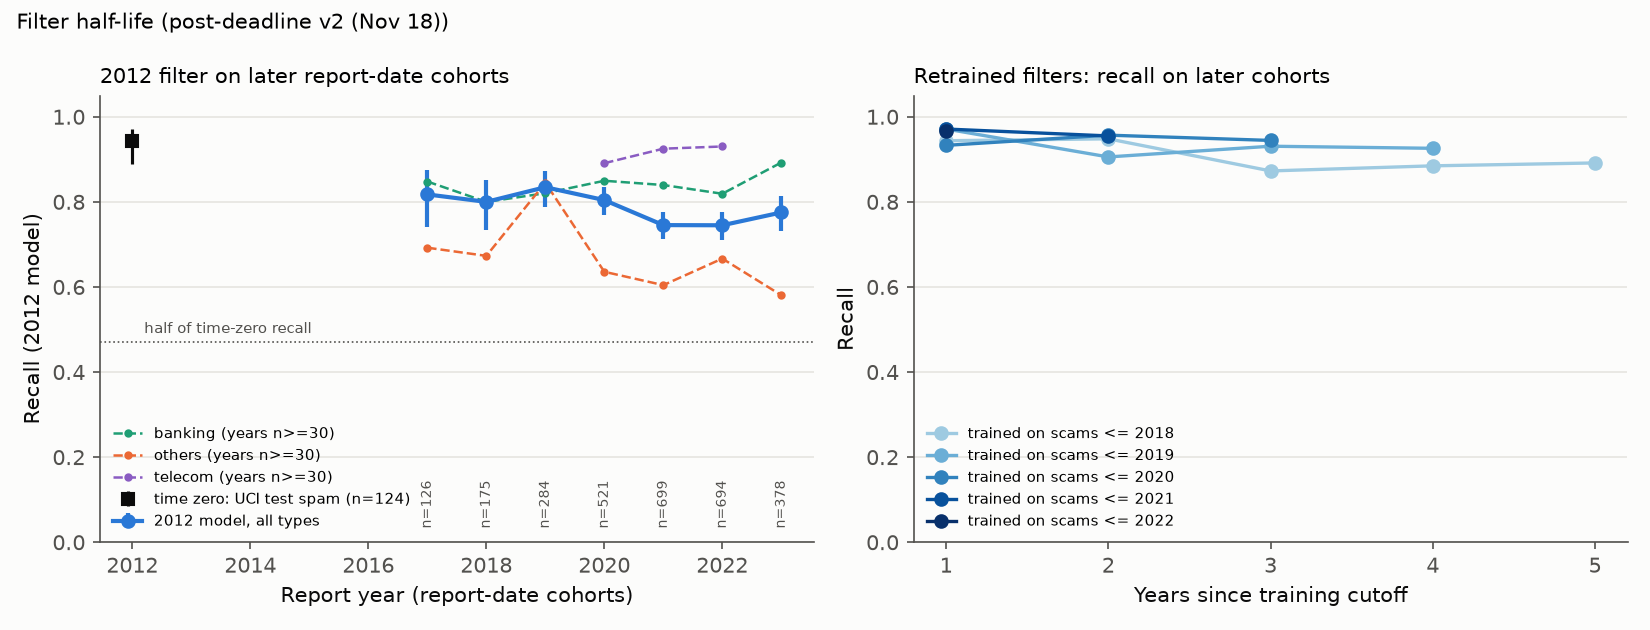

In [12]:
hl = V["half_life"]
print("time zero (UCI test spam):", hl["time_zero_2012_model"]["uci_test_spam_recall"],
      "| without near-duplicates of training spam:", hl["time_zero_2012_model"]["uci_test_spam_recall_without_near_dup_0.9"]["rate"])
display(pd.DataFrame(hl["by_year_word_2012"]))
print("slope per year (cohorts n >= 100):", hl["linear_slope_per_year_word_2012_years_with_n_ge_100"])
print("half-life:", hl["half_life_note"])
display(R("half_life_rolling_cutoff.csv"))
fig("half_life.png")

**Reading.** Recall drops in one step from 2012 spam to 2017-2023 reports, then stays roughly flat. The gap is an era or dataset shift, not a smooth yearly decline, so we do not claim the filter "decays every year". Filters retrained with later cutoffs keep high recall for several years.

## 9. Multilingual (item 6)
The same non-English scams, scored twice through the same model: raw text, and the English translation that came with the dataset (an **oracle reference**: a real deployment would need on-device translation of unverified quality). OOV share = share of tokens the 2012 model never saw. `char_multilingual` = a char n-gram model trained on raw text in all languages.

In [13]:
ml = V["multilingual"]
display(pd.DataFrame(ml["paired_raw_vs_translation"]).T[["n", "recall_raw", "recall_translation_oracle", "native_english_2022_24_recall"]])
display(pd.DataFrame(ml["oov_share_vs_word_2012_vocabulary"]).T)
cm = ml["char_multilingual"]
print("char_multilingual recall on raw non-English test:", cm["recall_all_test_languages"]["raw_char_multilingual"],
      "| MOZ legit false alarms:", cm["moz_portuguese_false_alarms"]["rate"])
display(R("multilingual_by_language.csv"))

,n,recall_raw,recall_translation_oracle,native_english_2022_24_recall
word_2012,8866.0,0.5080,0.6959,0.7565
char_2012,8866.0,0.5229,0.7150,0.6944
word_fixed,8866.0,0.7672,0.9768,0.9657
fix_plus_real_ham,8866.0,0.7013,0.9640,0.9481
fix_plus_benign,8866.0,0.7803,0.9815,0.9741


,pooled_token_share,mean_per_message
nonenglish_raw,0.7604,0.7686
nonenglish_translation,0.2097,0.2149
english_2022_24_test,0.2347,0.2397
uci_test,0.0910,0.0952


char_multilingual recall on raw non-English test: 0.9897 | MOZ legit false alarms: 0.9608


,language,n,raw_word_2012,tr_word_2012,raw_char_2012,raw_char_multilingual,ci95_raw_char_multilingual
0,Spanish,2901,0.4843,0.6936,0.5588,0.9979,"[0.9955, 0.9991]"
1,Dutch,1167,0.4936,0.7892,0.4996,0.9966,"[0.9912, 0.9987]"
2,French,798,0.4586,0.7130,0.6667,0.9975,"[0.9909, 0.9993]"
3,German,551,0.5318,0.6279,0.4192,0.9855,"[0.9716, 0.9926]"
4,Italian,486,0.4321,0.6893,0.4671,0.9979,"[0.9884, 0.9996]"
5,Indonesian,242,0.6942,0.6405,0.4504,0.9545,"[0.9205, 0.9744]"
6,Portuguese,214,0.5467,0.7523,0.6542,0.9953,"[0.974, 0.9992]"
7,Japanese,163,0.3436,0.4479,0.3313,0.9816,"[0.9473, 0.9937]"


**Reading.** Translation closes much of the gap for the 2012 model. The multilingual char model catches almost every non-English scam, but it flags almost every Portuguese legitimate text too: it learned "non-English = scam", the same trap as the naive fix. It is not shipped.

## 10. Learning curve (item 7)
Is the fix just "more data"? We add 0, 100, 500, 1,000 and all early scams (three seeds for subsamples) to two bases: the naive fix and the fix with real legitimate SMS. The spec asked for 2,000; only 1,809 early scams exist.

2,000 requested in the spec; the early pool has only 1809 rows, so 'all' = 1809. Subsample sizes use 3 seeds (mean, min, max shown).


,base,early_scams_added,runs,late_recall_mean,late_recall_min,late_recall_max,synthetic_fa_mean,india_fa_mean,moz_fa_mean
0,fix_plus_real_ham,0,1,0.2241,0.2241,0.2241,0.2000,0.1612,0.2214
1,fix_plus_real_ham,100,3,0.7472,0.6944,0.7935,0.2666,0.2938,0.2535
2,fix_plus_real_ham,500,3,0.9015,0.8889,0.9157,0.6111,0.5049,0.4040
3,fix_plus_real_ham,1000,3,0.9416,0.9370,0.9444,0.8667,0.6371,0.5288
4,fix_plus_real_ham,1809,1,0.9481,0.9481,0.9481,0.8667,0.6562,0.5305
5,naive_fix,0,1,0.7565,0.7565,0.7565,0.3667,0.8224,0.3937
6,naive_fix,100,3,0.8957,0.8917,0.9000,0.7778,0.9402,0.4136
7,naive_fix,500,3,0.9355,0.9250,0.9417,0.9667,0.9879,0.4849
8,naive_fix,1000,3,0.9540,0.9435,0.9620,1.0000,0.9934,0.5566
9,naive_fix,1809,1,0.9657,0.9657,0.9657,1.0000,0.9951,0.6250


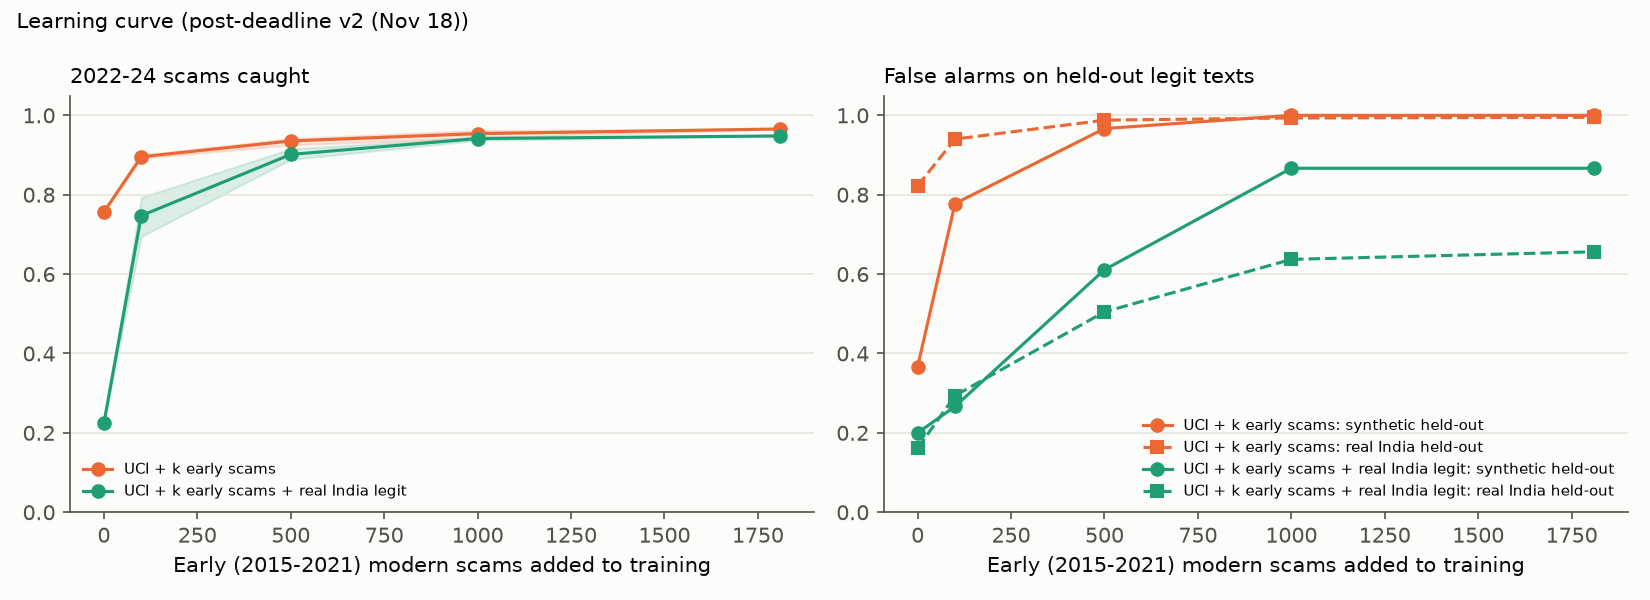

In [14]:
print(V["learning_curve"]["note"])
display(pd.DataFrame(V["learning_curve"]["summary"]))
fig("learning_curve.png")

**Reading.** More scams raise recall and false alarms together. With real legitimate texts in training, false alarms rise more slowly but still rise.

## 11. Threshold discipline (item 8)
Each threshold is chosen on out-of-fold predictions of the model's own training data, never on a test set. Default rule: minimise 5 x missed scams + 1 x false alarms (cost ratio 5:1). Alternative rule: the lowest threshold with at most 10% out-of-fold false alarms on the India training texts.

In [15]:
td = V["threshold_discipline"]
print(td["rule"]); print("alternative:", td["alternative_rule"])
display(pd.DataFrame(td["thresholds"]).T)

each threshold is chosen on out-of-fold predictions of the model's own training data (5 folds; group-aware when India rows are in training), minimising 5 x missed scams + 1 x false alarms; frozen before any 2022+ or held-out evaluation
alternative: false-alarm budget: lowest threshold with <= 10% out-of-fold false alarms on India-train legit


,threshold,fa_budget_threshold
word_2012,0.32,NaN
char_2012,0.34,NaN
word_fixed,0.24,NaN
char_fixed,0.30,NaN
fix_plus_benign,0.20,NaN
char_fix_plus_benign,0.30,NaN
fix_plus_real_ham,0.30,0.94
char_fix_plus_real_ham,0.31,0.94
fix_plus_real_ham_and_benign,0.29,0.92
char_multilingual,0.22,NaN


## 12. Prototype design: model selection and the three-tier triage (item 10)
The model and its threshold rule are chosen on validation data only (2021 scams for recall, half of the India training groups for false alarms; no 2022+ data, no MOZ, no India test groups), by the lowest expected cost per message at an ASSUMED 5% scam rate.

Tiers (warn-only, never blocks):
- **RED** "Likely scam - do not tap, do not reply": the model flags AND the text has a link or phone number.
- **YELLOW** "Ask family before replying": the model flags with no link or phone, OR a rule fires (asks for a code, PIN or password; a "hi mum / new number / wrong number" opener).
- **GREEN** "No warning signs found": never worded as "safe".

The tiers, the rules and the strict threshold were designed after the v1 results were seen (post-hoc), then frozen and evaluated. The India and Mozambique sets were looked at during exploration. The selection table also scores, for comparison only, a 10% false-alarm threshold on India A1 for models not trained on India texts, and the two link rules.

lowest validation expected cost per message = 5 x 0.05 x (1 - recall) + 1 x 0.95 x false-alarm rate (5% scam rate ASSUMED; cost ratio 5:1 as in v1)


,model,threshold_rule,threshold,val_scam_recall_2021,val_scam_n,val_real_legit_false_alarms,val_real_legit_n,val_expected_cost_per_message
0,char_fix_plus_real_ham,fa_budget_10pct_oof,0.97,0.5250,699,0.0632,364,0.1788
1,fix_plus_real_ham_and_benign,fa_budget_10pct_oof,0.98,0.4192,699,0.0714,364,0.2131
2,fix_plus_real_ham,fa_budget_10pct_oof,0.98,0.4435,699,0.0797,364,0.2148
3,word_2012,fa_budget_10pct_on_india_a1,0.95,0.1216,699,0.1236,364,0.3370
4,char_fix_plus_benign,fa_budget_10pct_on_india_a1,0.99,0.5279,699,0.3516,364,0.4521
5,rule_link_only,fixed rule (no threshold),NaN,0.4649,699,0.4176,364,0.5305
6,fix_plus_benign,fa_budget_10pct_on_india_a1,0.99,0.4778,699,0.4258,364,0.5351
7,word_fixed,fa_budget_10pct_on_india_a1,0.99,0.4864,699,0.4863,364,0.5903
8,rule_link_or_phone,fixed rule (no threshold),NaN,0.5637,699,0.6676,364,0.7433
9,char_fix_plus_real_ham,cost_5to1_oof,0.29,0.9213,699,0.8214,364,0.8000


chosen: {'model': 'char_fix_plus_real_ham', 'threshold_rule': 'fa_budget_10pct_oof'} | shipped threshold: 0.94


,set,n,red,yellow,green,red_or_yellow,red_ci95,red_or_yellow_ci95
0,scams_2022_24_english,1080,0.3954,0.2611,0.3435,0.6565,"[0.3666, 0.4249]","[0.6276, 0.6842]"
1,scams_2022_24_cluster_safe,927,0.3743,0.2395,0.3862,0.6138,"[0.3438, 0.4059]","[0.5821, 0.6446]"
2,scams_undated_english,12364,0.4267,0.2556,0.3177,0.6823,"[0.418, 0.4355]","[0.674, 0.6905]"
3,scams_nonenglish_translation_oracle,8866,0.3947,0.2887,0.3166,0.6834,"[0.3845, 0.4049]","[0.6736, 0.693]"
4,scams_nonenglish_raw_text,8866,0.1093,0.0521,0.8386,0.1614,"[0.103, 0.116]","[0.1539, 0.1692]"
5,synthetic_scam_twins,40,0.5750,0.1750,0.2500,0.7500,"[0.4219, 0.7149]","[0.5981, 0.8581]"
6,synthetic_legit_heldout,30,0.0333,0.1333,0.8333,0.1667,"[0.0059, 0.1667]","[0.0734, 0.3356]"
7,real_legit_india_heldout,608,0.1168,0.1118,0.7714,0.2286,"[0.0936, 0.1447]","[0.197, 0.2636]"
8,real_legit_moz_portuguese,1608,0.0187,0.0031,0.9782,0.0218,"[0.0131, 0.0265]","[0.0157, 0.0301]"
9,uci_test_ham,903,0.0011,0.0022,0.9967,0.0033,"[0.0002, 0.0062]","[0.0011, 0.0097]"


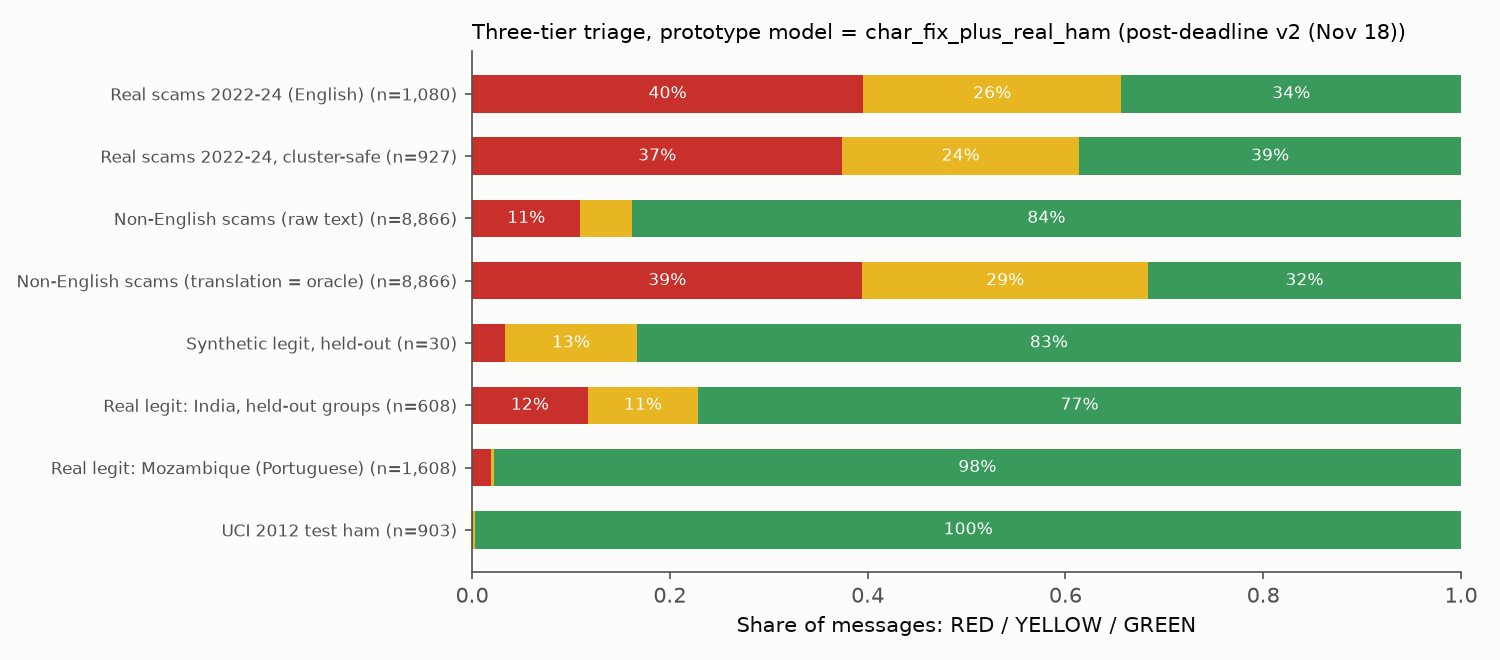

In [16]:
print(V["model_selection"]["rule"])
display(R("model_selection_validation.csv"))
print("chosen:", V["model_selection"]["chosen"], "| shipped threshold:", V["triage"]["threshold"])
display(R("triage_tiers.csv"))
fig("triage_tiers.png")

### Live check: does the saved model reproduce `metrics.json`?
We load `models/model_shipped.joblib`, score the 2022-24 test scams, apply the same tier function and compare with the stored shares.

In [17]:
import joblib
B = joblib.load("models/model_shipped.joblib"); m, th = B["pipeline"], B["threshold"]
def tiers(texts, norms):
    p = m.predict_proba(list(norms))[:, 1]
    return np.array([sd.triage_tier(pp, th, n, t) for pp, n, t in zip(p, norms, texts)])
L = d["late"].copy(); L["tier"] = tiers(L["text"], L["norm"]); L["warned"] = L["tier"] != "GREEN"
live = {"RED": round(float((L["tier"] == "RED").mean()), 4), "RED or YELLOW": round(float(L["warned"].mean()), 4)}
stored = {"RED": V["triage"]["sets"]["scams_2022_24_english"]["share_red"]["rate"],
          "RED or YELLOW": V["triage"]["sets"]["scams_2022_24_english"]["share_red_or_yellow"]["rate"]}
print("live:", live, "| stored:", stored, "| match:", live == stored)

live: {'RED': 0.3954, 'RED or YELLOW': 0.6565} | stored: {'RED': 0.3954, 'RED or YELLOW': 0.6565} | match: True


**Reading.** Against the link-only rule, the triage warns on more 2022-24 scams and on fewer held-out India legit texts. It does not beat the link-only rule on Mozambique legit texts or on the 30 held-out synthetic legit texts, and it misses about a third of 2022-24 scams (GREEN).

## 13. Does it work equally well for every group?
Per scam type, per message length and per language, for the prototype triage (share warned = RED or YELLOW). These per-group numbers are stored in `results/metrics.json` under `v2.triage`; the cell below prints them and re-computes them live from the saved model as a check. Wilson 95% intervals are shown because several groups are small. We have no age or gender data, so we cannot check those groups.

In [18]:
TV = V["triage"]
display(pd.DataFrame(TV["by_scam_type_2022_24"])); display(pd.DataFrame(TV["by_length_bucket_2022_24"]))
display(pd.DataFrame(TV["by_language_nonenglish_top8"]))
display(pd.DataFrame({k: {"n": v["n"], "warned_raw": v["warned_raw"]["rate"], "warned_translation_oracle": v["warned_translation_oracle"]["rate"]}
                      for k, v in TV["nonenglish_by_report_year_cohort"].items()}).T)
u = TV["undated_near_copy_check"]
print("undated English scams with a near-copy in training:", u["with_near_copy_in_training"]["rate"], "|", u["note"])
# Live re-check from the saved model.
live_type = L.groupby("scam_type")["warned"].mean().round(4).to_dict()
stored_type = {r["scam_type"]: r["rate"] for r in TV["by_scam_type_2022_24"]}
N = d["nonen"].copy()
N["warned_raw"] = tiers(N["text"], N["norm"]) != "GREEN"
live_lang = N.groupby("language")["warned_raw"].mean().round(4).to_dict()
print("per-type live == stored:", all(live_type[k] == v for k, v in stored_type.items()),
      "| per-language raw live == stored:", all(live_lang[r["language"]] == r["warned_raw"] for r in TV["by_language_nonenglish_top8"]))

,scam_type,n,rate,ci95
0,banking,468,0.8440,"[0.8084, 0.8741]"
1,others,246,0.4431,"[0.3824, 0.5056]"
2,government,99,0.6869,"[0.59, 0.7698]"
3,spam,96,0.4167,"[0.3231, 0.5166]"
4,delivery,87,0.5517,"[0.4472, 0.6518]"
5,telecom,56,0.6964,"[0.5666, 0.801]"
6,wrong number,24,0.2500,"[0.12, 0.449]"
7,hey mum/dad,4,1.0000,"[0.5101, 1.0]"


,len_bucket,n,rate,ci95
0,b 80-159,644,0.7267,"[0.691, 0.7597]"
1,c 160-319,234,0.6795,"[0.6172, 0.736]"
2,a <80 chars,152,0.3026,"[0.2352, 0.3798]"
3,d 320+,50,0.7200,"[0.5833, 0.8253]"


,language,n,warned_raw,warned_translation_oracle
0,Spanish,3191,0.2250,0.7809
1,Dutch,1551,0.0974,0.7988
2,French,870,0.2908,0.6805
3,German,590,0.0525,0.6356
4,Italian,534,0.0618,0.6536
5,Indonesian,329,0.0274,0.3526
6,Portuguese,247,0.1943,0.6680
7,Japanese,173,0.1734,0.4451


,n,warned_raw,warned_translation_oracle
dated_2021_or_earlier,989.0,0.1254,0.6805
dated_2022_or_later,509.0,0.2534,0.7033
undated,7368.0,0.1599,0.6824


undated English scams with a near-copy in training: 0.1055 | the undated set is not cluster-safe; only the 2022-24 cluster-safe set is


per-type live == stored: True | per-language raw live == stored: True


## 14. Where it fails
Five real 2022-24 reports (public IMC25 data, already anonymised by its authors) that the prototype triage leaves GREEN, picked by a fixed rule stored in `metrics.json`, and the two shortest held-out synthetic legit texts it warns on (synthetic, written with AI assistance). Several misses read like genuine notices, so some may be label noise (our assumption, not checked). The second table lists more GREEN misses, shortest first.

In [19]:
fe = V["triage"]["failure_examples"]
print(fe["rule"])
display(pd.DataFrame(fe["missed_scams_green"])); display(pd.DataFrame(fe["false_alarms_synthetic"]))
miss = L[~L["warned"]]
display(miss["scam_type"].value_counts().to_frame("missed (GREEN)"))
display(miss.assign(chars=miss["text"].str.len()).sort_values("chars")[["scam_type", "year", "text"]].head(12))

missed scams: real 2022-24 reports left GREEN; for each of the 5 scam types with the most GREEN misses, the shortest text of at least 40 characters. False alarms: the 2 shortest held-out synthetic legit texts that got RED or YELLOW.


,scam_type,year,chars,text
0,others,2023,43,Tap to reset your Instagram password: <URL>
1,banking,2022,41,Collect request from PAYU for <DATE_TIME>
2,spam,2022,41,Breaking: USA Says Goodbye to Dr Oz:<URL>
3,delivery,2022,42,<URL> has been reported as a malware site.
4,government,2022,73,"Dear IEC Holder, It is mandatory to update your IEC before <DATE_TIME>..."


,category,tier,text,label
0,pharmacy,YELLOW,Your copay for today's pickup is $10.00. Pay at the counter.,"synthetic, written with AI assistance"
1,delivery,YELLOW,Your parcel will arrive tomorrow between 10am and 2pm. No action needed.,"synthetic, written with AI assistance"


,missed (GREEN)
scam_type,
others,137
banking,73
spam,56
delivery,39
government,31
wrong number,18
telecom,17


,scam_type,year,text
724,wrong number,2023.0,hello
596,others,2022.0,P4kai: 1
1057,others,2023.0,Fuck off
1008,others,2023.0,Thank you 🙏🏻
948,wrong number,2023.0,How are you doing
934,others,2023.0,(KYC) regulations
188,others,2022.0,This is your fb pg
581,others,2022.0,fine fr no parking
634,others,2022.0,You have received U
888,others,2023.0,Didnot get my order


## 15. Try it
`triage(text)` returns the tier, the scam probability, plain-language reasons and the top words (words whose removal lowers the score most). The examples are written for this notebook (not real messages and not from the stress set); none is a real person's message.

In [20]:
for t in ["Your package could not be delivered. Update your address here: http://parcel-help.com",
          "Your First Harbor Bank verification code is 482913. It expires in 10 minutes. We will never call or text to ask for this code.",
          "Reminder: your credit card payment of $85.00 is due on 12/05. Pay in the app or at your branch.",
          "Hi mum, this is my new number, my phone broke. Can you text me back here?"]:
    r = triage(t)
    print(f"{r['tier']:6s} p={r['scam_probability']}  top words: {r['top_words']}\n   {t}\n   reasons: {r['reasons']}\n")

RED    p=0.9925  top words: ['package', '[a web link]', 'your', 'here:', 'update']
   Your package could not be delivered. Update your address here: http://parcel-help.com
   reasons: ['The model scores this text 0.99, at or above its warning level 0.94.', 'It contains a web link. Do not tap links in unexpected texts.']

GREEN  p=0.7662  top words: ['expires', '[a number]', 'text', 'your', 'first']
   Your First Harbor Bank verification code is 482913. It expires in 10 minutes. We will never call or text to ask for this code.
   reasons: ['No warning signs found. This does not prove the message is safe. Never share a one-time code, PIN or password.']

YELLOW p=0.9955  top words: ['[a money amount]', 'your', 'payment', '[a number]', 'due']
   Reminder: your credit card payment of $85.00 is due on 12/05. Pay in the app or at your branch.
   reasons: ['The model scores this text 1.00, at or above its warning level 0.94.']

YELLOW p=0.1318  top words: ['text', 'new', 'this', 'phone', 'you'

## 16. Limitations
- The India set is one person's inbox. Brand-or-template grouping reduces but does not remove shared style.
- Mozambique rates mix language shift with time shift. Both real legit sets were looked at during exploration before these numbers were final.
- The synthetic legit set is small (60; 30 held out) and written with AI assistance.
- The 5% scam rate is an assumption, not a measurement.
- The selection validation set is small; a different seed could pick a different model.
- The tiers, rules and strict threshold are post-hoc designs, frozen before this evaluation.
- Report-date cohorts are not send dates.

Full tables: `docs/RESULTS_DETAIL.md`. This project is a prototype and is not financial advice.